# Load Packages

In [31]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import Dataset

In [32]:
data = pd.read_excel('Data/GSE245759_normalized_counts.txt/GSE245759_normalized_counts.xlsx')

# Data Cleaning and EDA

Remove the samples I am not interested in keeping

In [33]:
data = data.drop(columns = ['CT+Pp-1','CT+Pp-2', 'CT+Pp-3', 'S+Pp-1', 'S+Pp-2', 'S+Pp-3',
                         'HS+Pp-1','HS+Pp-2', 'HS+Pp-3', 'S+HS+Pp-1', 'S+HS+Pp-2', 'S+HS+Pp-3' ])

To make the dataframe easier to work with, I need to change the gene names from a column to the index. That way the only values in my dataframe are numbers

In [34]:
data = data.set_index('genes')

Filter the dataset for low-expression genes. Only keep the genes with counts >= 10 in 25% of samples. 

In [35]:
print("Number of samples before filtering: ", data.shape[0])

#check which samples have expression >= 10
expressed = data >= 10

#how many samples in each gene meet the count threshold
expressed_samples = expressed.sum(axis=1)

#filter the data to only keep the samples where threshold is met in 
#25% of samples
data = data[expressed_samples >= 3]

print("Number of samples after filtering: ", data.shape[0])

Number of samples before filtering:  34075
Number of samples after filtering:  20390


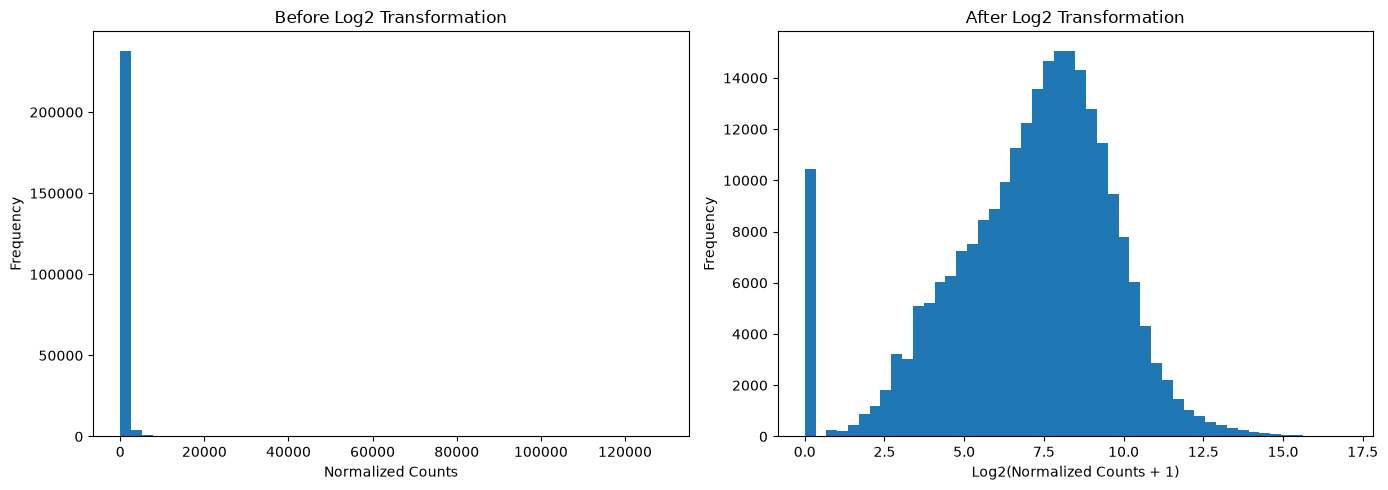

In [40]:
# Log2 transform normalized counts
data_log = np.log2(data + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Histogram BEFORE log transformation
axes[0].hist(data.values.flatten(), bins=50)
axes[0].set_title('Before Log2 Transformation')
axes[0].set_xlabel('Normalized Counts')
axes[0].set_ylabel('Frequency')

# Histogram AFTER log transformation
axes[1].hist(data_log.values.flatten(), bins=50)
axes[1].set_title('After Log2 Transformation')
axes[1].set_xlabel('Log2(Normalized Counts + 1)')
axes[1].set_ylabel('Frequency')

plt.tight_layout()

plt.savefig('images/data_distribution.png', dpi=300, bbox_inches='tight')
plt.show()